# Preferred Attack Angle — MLB & Frontier League

Implements the **Marshall (2017 FanGraphs Community) methodology** for Preferred Attack Angle (PAA):

1. Bin BBE by launch angle (3° bins over the −30° to 60° fit window)
2. Within each bin, keep the **top 20% of BBE by exit velocity** (the EV envelope)
3. Fit a parabola to the envelope; **Method 1** = launch angle at the parabola peak
4. **Method 2** = mean launch angle of the **top 15 BBE by EV**
5. **PAA = average of Method 1 and Method 2**

Conventions:
- **MLB**: pybaseball Statcast (2024+2025 parquet caches), `launch_speed`/`launch_angle`/`stand`. Spray angle from `hc_x`/`hc_y`. Bonus: validate PAA against Statcast's *measured* `attack_angle`.
- **FL**: Supabase, `pitch_call='in_play'`, `exit_speed`/`angle`/`batter_side`/`direction`. Pull = `direction < −15` (RHB) / `> +15` (LHB). Air = LA ≥ 10.

Outputs: batter-level correlations of PAA vs **Pull%, Air%, PullAir%** in both leagues.

## 1. Imports & Config

In [1]:
import warnings
warnings.filterwarnings("ignore")

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from scipy import stats
from scipy.stats import spearmanr
from dotenv import load_dotenv
from sqlalchemy import create_engine, text

pd.set_option("display.max_columns", 60)
pd.set_option("display.float_format", "{:.3f}".format)

# ── PAA methodology parameters (Marshall 2017) ────────────────────────────────
ANGLE_MIN, ANGLE_MAX = -30, 60     # fit window (same as HR_AB notebook)
BIN_WIDTH        = 3               # ~3° LA bins per the article
TOP_FRAC_PER_BIN = 0.20            # top 20% of BBE by EV within each bin
TOP_N_METHOD2    = 15              # method 2: mean LA of top-15 BBE by EV

# ── Qualification thresholds ──────────────────────────────────────────────────
MIN_BBE_MLB = 100                  # article uses 100 BBE
MIN_BBE_FL  = 50                   # FL: shorter season (HR_AB used ~51)

# ── Spray / air conventions ───────────────────────────────────────────────────
PULL_CUTOFF_DEG = 15               # validated: reproduces ~.36 league Pull% in FL
AIR_LA_MIN      = 10               # LD/FB/PU per HR_AB la_classifier

print("Config OK")

Config OK


## 2. Preferred Attack Angle — Methodology

One generic function, column names passed in so it works on both schemas.

In [2]:
def preferred_attack_angle(df, la_col, ev_col):
    """
    Marshall (2017) Preferred Attack Angle for a single batter's BBE.

    Method 1: 3° LA bins → top 20% by EV per bin → parabola fit → peak LA.
    Method 2: mean LA of the top-15 BBE by EV.
    PAA      = mean(Method 1, Method 2).

    Returns (paa, method1, method2, n_envelope) — NaN-safe.
    """
    g = df.dropna(subset=[la_col, ev_col])
    g = g[(g[la_col] >= ANGLE_MIN) & (g[la_col] <= ANGLE_MAX)]
    if len(g) < 10:
        return np.nan, np.nan, np.nan, 0

    # ── Method 2: mean LA of top-15 by EV (or top 20% if fewer than 15 avail)
    k2 = min(TOP_N_METHOD2, max(3, int(np.ceil(0.2 * len(g)))))
    method2 = g.nlargest(k2, ev_col)[la_col].mean()

    # ── Method 1: envelope parabola
    bins = np.arange(ANGLE_MIN, ANGLE_MAX + BIN_WIDTH, BIN_WIDTH)
    g = g.copy()
    g["_bin"] = pd.cut(g[la_col], bins=bins, include_lowest=True)

    env_idx = []
    for _, grp in g.groupby("_bin", observed=True):
        if len(grp) == 0:
            continue
        k = max(1, int(np.ceil(TOP_FRAC_PER_BIN * len(grp))))
        env_idx.extend(grp.nlargest(k, ev_col).index)

    env = g.loc[env_idx]
    if len(env) < 5:
        # envelope too thin for a stable parabola — fall back to method 2 only
        return method2, np.nan, method2, len(env)

    a, b, c = np.polyfit(env[la_col], env[ev_col], deg=2)

    if a < 0:
        vertex = -b / (2 * a)
        if ANGLE_MIN <= vertex <= ANGLE_MAX:
            method1 = vertex
        else:
            # vertex outside window — take argmax of fitted curve on the window
            xs = np.linspace(ANGLE_MIN, ANGLE_MAX, 361)
            method1 = xs[np.argmax(np.polyval([a, b, c], xs))]
    else:
        # upward parabola (degenerate) — argmax on window edge is meaningless;
        # use envelope's own EV-max point instead
        method1 = env.loc[env[ev_col].idxmax(), la_col]

    paa = np.nanmean([method1, method2])
    return paa, method1, method2, len(env)


def batter_paa_table(df, batter_col, la_col, ev_col, extra_group=None):
    """PAA per batter (optionally per extra_group e.g. year)."""
    keys = [batter_col] + ([extra_group] if extra_group else [])
    rows = []
    for key, g in df.groupby(keys):
        key = key if isinstance(key, tuple) else (key,)
        paa, m1, m2, n_env = preferred_attack_angle(g, la_col, ev_col)
        rows.append(dict(zip(keys, key)) | {
            "PAA": paa, "PAA_parabola": m1, "PAA_top15": m2,
            "BBE": len(g.dropna(subset=[la_col, ev_col])),
            "n_envelope": n_env,
        })
    return pd.DataFrame(rows)

print("PAA functions defined")

PAA functions defined


## 3. MLB — Load Statcast (2024 + 2025 caches)

In [3]:
def load_statcast(cache_path):
    p = Path(cache_path)
    if p.exists():
        print(f"Loading {p} …")
        return pd.read_parquet(p)
    raise FileNotFoundError(
        f"{p} not found — run the attack_angle notebooks first to build the cache."
    )

raw = pd.concat([
    load_statcast("statcast_2024.parquet"),
    load_statcast("statcast_2025.parquet"),
], ignore_index=True)

# BBE only: in-play with tracked EV/LA
mlb = raw[
    (raw["type"] == "X") &
    raw["launch_speed"].notna() &
    raw["launch_angle"].notna() &
    raw["hc_x"].notna() & raw["hc_y"].notna() &
    raw["stand"].notna() &
    raw["batter"].notna()
].copy()

print(f"MLB BBE rows: {len(mlb):,}   batters: {mlb['batter'].nunique():,}")

Loading statcast_2024.parquet …
Loading statcast_2025.parquet …
MLB BBE rows: 252,710   batters: 1,241


## 4. MLB — Spray Angle & Batter Metrics

Standard Statcast spray-angle formula from hit coordinates, mirrored so the ±15° pull convention matches the FL `direction` convention (checked against league Pull% below).

In [4]:
# Spray angle in degrees from hit coordinates (standard Statcast transform).
# Negative = LF side, positive = RF side (matches TrackMan direction sign).
mlb["spray_deg"] = np.degrees(
    np.arctan((mlb["hc_x"] - 125.42) / (198.27 - mlb["hc_y"]))
) * 0.75

# Pull per HR_AB convention: RHB pull = spray < -15, LHB pull = spray > +15
mlb["is_pull"] = np.where(
    mlb["stand"] == "R", mlb["spray_deg"] < -PULL_CUTOFF_DEG,
                         mlb["spray_deg"] >  PULL_CUTOFF_DEG)
mlb["is_air"]  = mlb["launch_angle"] >= AIR_LA_MIN

print(f"MLB league Pull%    : {mlb['is_pull'].mean():.3f}   (expect ≈ .36)")
print(f"MLB league Air%     : {mlb['is_air'].mean():.3f}")
print(f"MLB league PullAir% : {(mlb['is_pull'] & mlb['is_air']).mean():.3f}")

MLB league Pull%    : 0.380   (expect ≈ .36)
MLB league Air%     : 0.560
MLB league PullAir% : 0.152


In [5]:
# PAA per MLB batter (pooled 2024-25)
mlb_paa = batter_paa_table(mlb, "batter", "launch_angle", "launch_speed")

spray_metrics = mlb.groupby("batter").agg(
    pull_pct     = ("is_pull", "mean"),
    air_pct      = ("is_air",  "mean"),
).reset_index()
pullair = mlb.groupby("batter").apply(
    lambda g: (g["is_pull"] & g["is_air"]).mean()
).rename("pull_air_pct").reset_index()

mlb_batters = (mlb_paa
    .merge(spray_metrics, on="batter")
    .merge(pullair, on="batter"))
mlb_q = mlb_batters[(mlb_batters["BBE"] >= MIN_BBE_MLB) &
                    mlb_batters["PAA"].notna()].copy()
print(f"Qualified MLB batters (≥{MIN_BBE_MLB} BBE): {len(mlb_q)}")
print(mlb_q["PAA"].describe().round(2))

Qualified MLB batters (≥100 BBE): 522
count   522.000
mean     10.760
std       5.540
min     -12.830
25%       7.400
50%      11.200
75%      14.390
max      24.990
Name: PAA, dtype: float64


### 4b. Sanity check — PAA vs Statcast's *measured* attack angle

Statcast reports true bat-tracking `attack_angle` (2024+). If the reverse-engineered PAA is valid, it should correlate strongly with each batter's mean measured attack angle. This is the ground-truth validation FL can't provide.

PAA vs measured attack angle (n=522):
  Pearson r  = 0.7827
  Spearman ρ = 0.7653   (p = 1.49e-101)


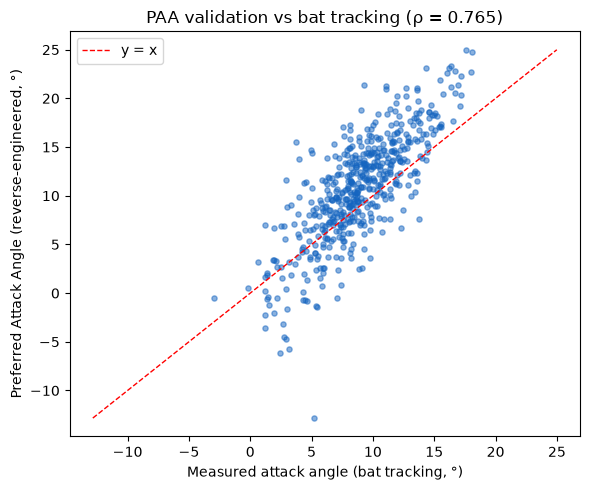

In [6]:
if "attack_angle" in raw.columns and raw["attack_angle"].notna().any():
    aa_meas = (raw[raw["attack_angle"].notna() & raw["batter"].notna()]
               .groupby("batter")["attack_angle"].agg(["mean", "count"])
               .rename(columns={"mean": "attack_angle_measured", "count": "n_swings"})
               .reset_index())
    chk = mlb_q.merge(aa_meas[aa_meas["n_swings"] >= 100], on="batter")
    r_p, _   = stats.pearsonr(chk["PAA"], chk["attack_angle_measured"])
    r_s, p_s = spearmanr(chk["PAA"], chk["attack_angle_measured"])
    print(f"PAA vs measured attack angle (n={len(chk)}):")
    print(f"  Pearson r  = {r_p:.4f}")
    print(f"  Spearman ρ = {r_s:.4f}   (p = {p_s:.2e})")

    fig, ax = plt.subplots(figsize=(6, 5))
    ax.scatter(chk["attack_angle_measured"], chk["PAA"], s=14, alpha=0.5, color="#1565C0")
    lims = [min(chk["attack_angle_measured"].min(), chk["PAA"].min()),
            max(chk["attack_angle_measured"].max(), chk["PAA"].max())]
    ax.plot(lims, lims, "r--", lw=1, label="y = x")
    ax.set_xlabel("Measured attack angle (bat tracking, °)")
    ax.set_ylabel("Preferred Attack Angle (reverse-engineered, °)")
    ax.set_title(f"PAA validation vs bat tracking (ρ = {r_s:.3f})")
    ax.legend(); plt.tight_layout(); plt.show()
else:
    print("attack_angle not in cache — skipping ground-truth validation")

## 5. MLB — Correlations: PAA vs Pull%, Air%, PullAir%

In [7]:
def corr_table(df, x_col, targets, label):
    print(f"{label}  (n={len(df)})")
    print(f"{'Metric':<12}  {'Pearson r':>10}  {'Spearman ρ':>10}  {'p-value':>10}")
    print("-" * 50)
    out = {}
    for name, col in targets.items():
        paired = df[[x_col, col]].dropna()
        r_p, _   = stats.pearsonr(paired[x_col], paired[col])
        r_s, p_s = spearmanr(paired[x_col], paired[col])
        print(f"{name:<12}  {r_p:>10.4f}  {r_s:>10.4f}  {p_s:>10.2e}")
        out[name] = (r_p, r_s, p_s)
    return out

TARGETS = {"Pull%": "pull_pct", "Air%": "air_pct", "PullAir%": "pull_air_pct"}

mlb_corrs = corr_table(mlb_q, "PAA", TARGETS,
                       f"MLB — PAA correlations (≥{MIN_BBE_MLB} BBE, 2024-25 pooled)")

MLB — PAA correlations (≥100 BBE, 2024-25 pooled)  (n=522)
Metric         Pearson r  Spearman ρ     p-value
--------------------------------------------------
Pull%             0.4354      0.4051    4.87e-22
Air%              0.5690      0.5508    9.61e-43
PullAir%          0.4888      0.4640    3.12e-29


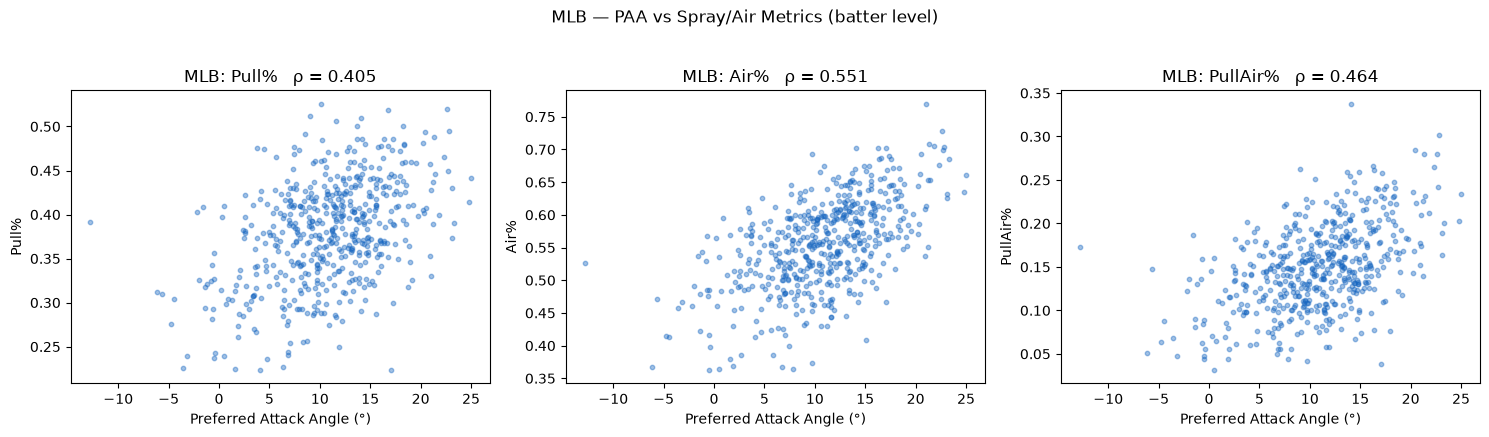

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, (name, col) in zip(axes, TARGETS.items()):
    ax.scatter(mlb_q["PAA"], mlb_q[col], s=10, alpha=0.4, color="#1565C0")
    r_s, _ = spearmanr(mlb_q["PAA"], mlb_q[col])
    ax.set_xlabel("Preferred Attack Angle (°)")
    ax.set_ylabel(name)
    ax.set_title(f"MLB: {name}   ρ = {r_s:.3f}")
plt.suptitle("MLB — PAA vs Spray/Air Metrics (batter level)", y=1.03)
plt.tight_layout(); plt.show()

## 6. Frontier League — Pull from Supabase

In [9]:
ENV_PATH = r"C:/Users/215nt/PycharmProjects/FLStuff/FLPitching/FLCommand/.env"

def get_engine():
    load_dotenv(ENV_PATH)
    host     = os.getenv("SUPABASE_HOST", "aws-1-us-east-1.pooler.supabase.com")
    port     = os.getenv("SUPABASE_PORT", "6543")
    dbname   = os.getenv("SUPABASE_DB",   "postgres")
    user     = os.getenv("SUPABASE_USER")
    password = os.getenv("SUPABASE_PASSWORD")
    return create_engine(
        f"postgresql+psycopg2://{user}:{password}@{host}:{port}/{dbname}?sslmode=require"
    )

SQL = """
SELECT
    batter,
    batter_team,
    batter_side,
    year,
    exit_speed,
    angle,
    direction
FROM pitches
WHERE pitch_call = 'in_play'
  AND exit_speed IS NOT NULL
  AND angle      IS NOT NULL
  AND direction  IS NOT NULL
  AND batter     IS NOT NULL
"""

engine = get_engine()
with engine.connect() as conn:
    fl_raw = pd.read_sql(text(SQL), conn)

print(f"FL BBE rows: {len(fl_raw):,}   batters: {fl_raw['batter'].nunique()}")
print(f"Years: {sorted(fl_raw['year'].unique())}")

FL BBE rows: 65,420   batters: 584
Years: [np.float64(2025.0), np.float64(2026.0), np.float64(nan)]


## 7. FL — Conventions & Batter Metrics

- Handedness: assert-mapped (no silent default, per attack_direction fix #3)
- Direction filtered to physical range ±45°
- Pull per HR_AB spray_classifier: RHB `direction < −15`, LHB `direction > +15` — validated to give ≈.36 league Pull%
- Air = LA ≥ 10 (LD/FB/PU)

In [12]:
FL_HAND_MAP = {"Left": "L", "Right": "R", "left": "L", "right": "R"}

n_before = len(fl_raw)
fl_raw = fl_raw[fl_raw["batter_side"] != "undefined"].copy()
print(f"Dropped {n_before - len(fl_raw):,} rows with undefined batter_side")

unmapped = fl_raw.loc[~fl_raw["batter_side"].isin(FL_HAND_MAP), "batter_side"].unique()
assert len(unmapped) == 0, f"Unmapped batter_side values: {list(unmapped)} — add to FL_HAND_MAP"

fl = fl_raw.copy()
fl["stand"] = fl["batter_side"].map(FL_HAND_MAP)

# physical spray range only (tracking errors outside ±45)
n_before = len(fl)
fl = fl[fl["direction"].between(-45, 45)].copy()
print(f"Direction outlier filter: dropped {n_before - len(fl):,} rows")

fl["is_pull"] = np.where(
    fl["stand"] == "R", fl["direction"] < -PULL_CUTOFF_DEG,
                        fl["direction"] >  PULL_CUTOFF_DEG)
fl["is_air"]  = fl["angle"] >= AIR_LA_MIN

print(f"FL league Pull%    : {fl['is_pull'].mean():.3f}   (expect ≈ .36)")
print(f"FL league Air%     : {fl['is_air'].mean():.3f}")
print(f"FL league PullAir% : {(fl['is_pull'] & fl['is_air']).mean():.3f}")

Dropped 0 rows with undefined batter_side
Direction outlier filter: dropped 4,314 rows
FL league Pull%    : 0.360   (expect ≈ .36)
FL league Air%     : 0.565
FL league PullAir% : 0.157


In [13]:
# PAA per FL batter (pooled across years; switch extra_group="year" for per-season)
fl_paa = batter_paa_table(fl, "batter", "angle", "exit_speed")

fl_spray = fl.groupby("batter").agg(
    pull_pct = ("is_pull", "mean"),
    air_pct  = ("is_air",  "mean"),
).reset_index()
fl_pullair = fl.groupby("batter").apply(
    lambda g: (g["is_pull"] & g["is_air"]).mean()
).rename("pull_air_pct").reset_index()

fl_batters = (fl_paa
    .merge(fl_spray, on="batter")
    .merge(fl_pullair, on="batter"))
fl_q = fl_batters[(fl_batters["BBE"] >= MIN_BBE_FL) &
                  fl_batters["PAA"].notna()].copy()
print(f"Qualified FL batters (≥{MIN_BBE_FL} BBE): {len(fl_q)}")
print(fl_q["PAA"].describe().round(2))

Qualified FL batters (≥50 BBE): 317
count   317.000
mean     13.470
std       5.070
min     -15.470
25%      10.790
50%      13.820
75%      16.860
max      29.810
Name: PAA, dtype: float64


## 8. FL — Correlations: PAA vs Pull%, Air%, PullAir%

In [14]:
fl_corrs = corr_table(fl_q, "PAA", TARGETS,
                      f"Frontier League — PAA correlations (≥{MIN_BBE_FL} BBE)")

Frontier League — PAA correlations (≥50 BBE)  (n=317)
Metric         Pearson r  Spearman ρ     p-value
--------------------------------------------------
Pull%             0.3798      0.3754    4.77e-12
Air%              0.6520      0.6491    2.61e-39
PullAir%          0.4752      0.4644    2.31e-18


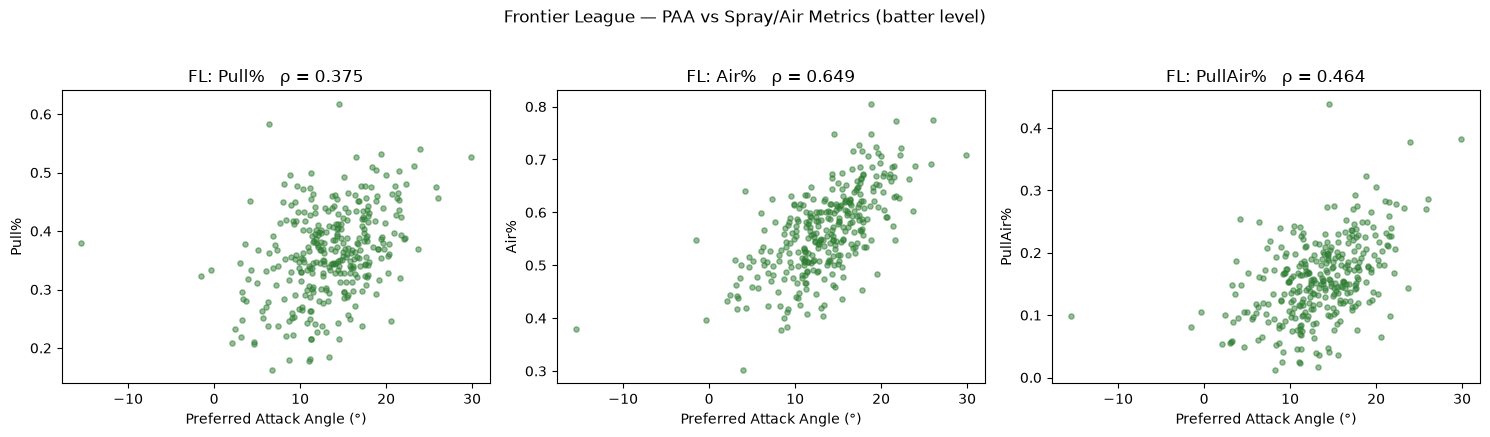

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, (name, col) in zip(axes, TARGETS.items()):
    ax.scatter(fl_q["PAA"], fl_q[col], s=14, alpha=0.5, color="#2E7D32")
    r_s, _ = spearmanr(fl_q["PAA"], fl_q[col])
    ax.set_xlabel("Preferred Attack Angle (°)")
    ax.set_ylabel(name)
    ax.set_title(f"FL: {name}   ρ = {r_s:.3f}")
plt.suptitle("Frontier League — PAA vs Spray/Air Metrics (batter level)", y=1.03)
plt.tight_layout(); plt.show()

## 9. Side-by-Side Summary

League   Metric   n  Pearson r  Spearman ρ  p-value
   MLB    Pull% 522      0.435       0.405 4.87e-22
   MLB     Air% 522      0.569       0.551 9.61e-43
   MLB PullAir% 522      0.489       0.464 3.12e-29
    FL    Pull% 317      0.380       0.375 4.77e-12
    FL     Air% 317      0.652       0.649 2.61e-39
    FL PullAir% 317      0.475       0.464 2.31e-18


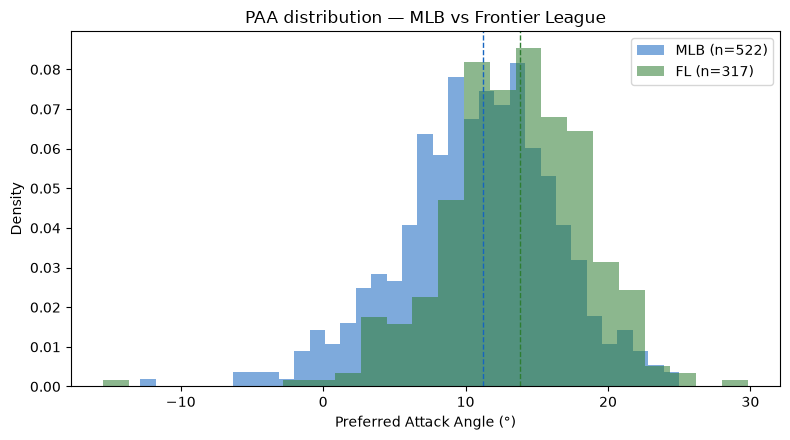


Saved → output/paa_mlb.csv, output/paa_fl.csv


In [16]:
summary_rows = []
for league, corrs, n in [("MLB", mlb_corrs, len(mlb_q)), ("FL", fl_corrs, len(fl_q))]:
    for metric, (r_p, r_s, p) in corrs.items():
        summary_rows.append({"League": league, "Metric": metric, "n": n,
                             "Pearson r": round(r_p, 4),
                             "Spearman ρ": round(r_s, 4),
                             "p-value": f"{p:.2e}"})
summary = pd.DataFrame(summary_rows)
print(summary.to_string(index=False))

# Distribution comparison
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hist(mlb_q["PAA"], bins=35, alpha=0.55, density=True, color="#1565C0", label=f"MLB (n={len(mlb_q)})")
ax.hist(fl_q["PAA"],  bins=25, alpha=0.55, density=True, color="#2E7D32", label=f"FL (n={len(fl_q)})")
ax.axvline(mlb_q["PAA"].median(), color="#1565C0", ls="--", lw=1)
ax.axvline(fl_q["PAA"].median(),  color="#2E7D32", ls="--", lw=1)
ax.set_xlabel("Preferred Attack Angle (°)")
ax.set_ylabel("Density")
ax.set_title("PAA distribution — MLB vs Frontier League")
ax.legend(); plt.tight_layout(); plt.show()

# Save leaderboards
Path("output").mkdir(exist_ok=True)
mlb_q.sort_values("PAA", ascending=False).to_csv("output/paa_mlb.csv", index=False)
fl_q.sort_values("PAA", ascending=False).to_csv("output/paa_fl.csv", index=False)
print("\nSaved → output/paa_mlb.csv, output/paa_fl.csv")